# code_130 · Learned vector fields and dissipative oscillator structure

**Book:** section 25.4. A self-contained scientific-learning laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_25_GUIDE.md), [run evidence](../CHAPTER_25_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_130).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=2930;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 2930


<a id="learned-dynamics-contract"></a>
 ## Learned continuous laws still require a numerical solver
 A unit-mass oscillator satisfies qdot=v and vdot=−1.7*q−0.25*v. Twenty initial conditions supply exact generated state and derivative labels over0–4; five development and five final initial conditions supply whole held-out trajectories. Fit a two-hidden-layer sixteen-unit unconstrained neural vector field and a two-parameter positive stiffness/damping field to source derivatives for1,200 Adam updates at0.01. All states, including velocity, are observed; this is derivative-supervised identification, not hidden-velocity or trajectory-only recovery. Final fixed-step RK4 rollouts extend to12. A native SciPy DOP853 solution is an independently refined reference. Separate mechanisms integrate the frozen neural field with a known control path and with known velocity diffusion. No adjoint implementation or learned diffusion is claimed.


,model,source_derivative_MSE,development_derivative_MSE,parameters,final_rollout_MSE,late_time_MSE,step_halving_RMS
0,Unconstrained neural ODE,7.243996e-06,5.811807e-06,354,4.412292e-05,6.212532e-05,2.526381e-07
1,Dissipative mechanical field,2.232869e-13,1.009085e-13,2,5.233078e-13,6.666654e-13,2.516245e-07


Mechanical coefficients: 1.700000285298384 0.25000119229678813
SDE moment evidence: {'known_velocity_diffusion': 0.2, 'paths': 512, 'horizon': 2.0, 'learned_drift_mean': [-0.0017329213064611524, -0.005460746482286169], 'learned_drift_covariance': [[0.02019261232912843, 0.003132658348555201], [0.003132658348555201, 0.02438127964953417]], 'linear_truth_covariance': [[0.020813185951907853, 0.001941447102553376], [0.0019414471025533783, 0.027087316552097493]], 'shared_Brownian_step_refinement_RMS': 0.0019331072054046211}


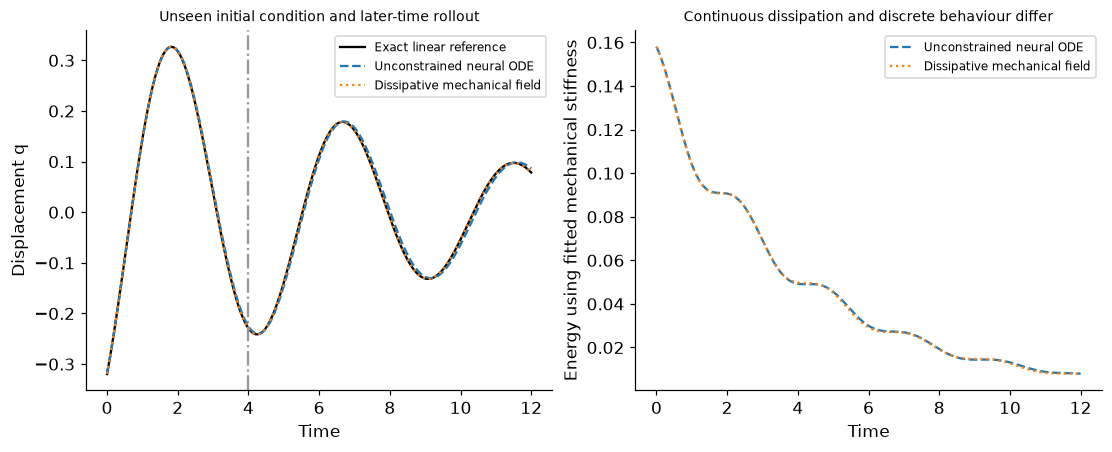

In [2]:
from scipy.integrate import solve_ivp
from scipy.linalg import expm,solve_continuous_lyapunov
A=np.array([[0.,1.],[-1.7,-.25]]);initial=rng.uniform(-1,1,(30,2));sample_times=np.linspace(0,4,21)
source=np.concatenate([np.stack([expm(A*t)@z for t in sample_times]) for z in initial[:20]]);target=source@A.T;X=torch.tensor(source);Y=torch.tensor(target)
class Mechanical(nn.Module):
    def __init__(self):super().__init__();self.raw=nn.Parameter(torch.zeros(2))
    def coefficients(self):return torch.nn.functional.softplus(self.raw)+1e-5
    def forward(self,z):
        k,c=self.coefficients();return torch.stack([z[...,1],-k*z[...,0]-c*z[...,1]],-1)
constructors={'Unconstrained neural ODE':lambda:nn.Sequential(nn.Linear(2,16),nn.Tanh(),nn.Linear(16,16),nn.Tanh(),nn.Linear(16,2)),'Dissipative mechanical field':Mechanical};models={};rows=[]
for name,constructor in constructors.items():
    torch.manual_seed(SEED);model=constructor();opt=torch.optim.Adam(model.parameters(),lr=.01)
    for step in range(1200):opt.zero_grad();loss=(model(X)-Y).square().mean();loss.backward();opt.step()
    models[name]=model;dev_state=torch.tensor(np.concatenate([np.stack([expm(A*t)@z for t in sample_times]) for z in initial[20:25]]));rows.append({'model':name,'source_derivative_MSE':float((model(X)-Y).square().mean().detach()),'development_derivative_MSE':float((model(dev_state)-dev_state@torch.tensor(A).T).square().mean().detach()),'parameters':sum(p.numel() for p in model.parameters())})
def rk4(model,z,step,steps):
    trajectory=[z]
    for j in range(steps):
        a=model(z);b=model(z+step*a/2);c=model(z+step*b/2);d=model(z+step*c);z=z+step*(a+2*b+2*c+d)/6;trajectory.append(z)
    return torch.stack(trajectory)
times=np.linspace(0,12,241);truth=np.stack([[expm(A*t)@z for z in initial[25:]] for t in times]);paths={}
for row in rows:
    m=models[row['model']]
    with torch.no_grad():p=rk4(m,torch.tensor(initial[25:]),.05,240).numpy();fine=rk4(m,torch.tensor(initial[25:]),.025,480).numpy()[::2]
    paths[row['model']]=p;row.update(final_rollout_MSE=float(np.mean((p-truth)**2)),late_time_MSE=float(np.mean((p[81:]-truth[81:])**2)),step_halving_RMS=float(np.sqrt(np.mean((p-fine)**2))))
mechanical=models['Dissipative mechanical field'];k,c=mechanical.coefficients().detach().numpy();z=torch.tensor(initial[25:]);field=mechanical(z);power=k*z[:,0]*field[:,0]+z[:,1]*field[:,1];torch.testing.assert_close(power,-c*z[:,1]**2,atol=1e-14,rtol=1e-12)
last=rk4(mechanical,torch.tensor(initial[25]),.05,20)[-1,0];autograd=torch.autograd.grad(last,mechanical.raw)[0][0].item();eps=1e-5;original=mechanical.raw.detach().clone()
with torch.no_grad():
    mechanical.raw[0]+=eps;plus=float(rk4(mechanical,torch.tensor(initial[25]),.05,20)[-1,0]);mechanical.raw.copy_(original);mechanical.raw[0]-=eps;minus=float(rk4(mechanical,torch.tensor(initial[25]),.05,20)[-1,0]);mechanical.raw.copy_(original)
finite=(plus-minus)/(2*eps);assert abs(autograd-finite)<1e-8
reference=[]
for tol in [1e-7,1e-10]:
    sol=solve_ivp(lambda t,z:A@z,[0,12],initial[25],method='DOP853',t_eval=times,rtol=tol,atol=tol*.01);assert sol.success;reference.append({'relative_tolerance':tol,'function_evaluations':sol.nfev,'max_state_error':float(np.max(np.abs(sol.y.T-truth[:,0])))})
neural=models['Unconstrained neural ODE'];dt=.01;control=np.sin(np.arange(201)*dt*3);changed_control=control.copy();changed_control[101:]+=4
def controlled(path):
    state=torch.zeros(2);result=[state.numpy().copy()]
    with torch.no_grad():
        for j in range(len(path)-1):state=state+dt*neural(state)+torch.tensor([0.,path[j+1]-path[j]]);result.append(state.numpy().copy())
    return np.array(result)
controlled_path=controlled(control);changed_path=controlled(changed_control);np.testing.assert_array_equal(controlled_path[:101],changed_path[:101])
# Itô Euler–Maruyama: frozen learned neural drift; prescribed constant velocity noise.
sigma=.2;increments=rng.normal(0,np.sqrt(dt),(200,512));B=np.array([[0.],[sigma]]);stationary=solve_continuous_lyapunov(A,-B@B.T);transition=expm(A*2);covariance=stationary-transition@stationary@transition.T
def stochastic(step,noise):
    state=torch.zeros((512,2))
    with torch.no_grad():
        for inc in noise:state=state+step*neural(state)+torch.stack([torch.zeros(512),sigma*torch.tensor(inc)],1)
    return state.numpy()
fine=stochastic(.01,increments);coarse=stochastic(.02,increments.reshape(100,2,512).sum(1));sde={'known_velocity_diffusion':sigma,'paths':512,'horizon':2.,'learned_drift_mean':fine.mean(0).tolist(),'learned_drift_covariance':np.cov(fine.T).tolist(),'linear_truth_covariance':covariance.tolist(),'shared_Brownian_step_refinement_RMS':float(np.sqrt(np.mean((fine-coarse)**2)))}
RESULTS.update(comparisons=rows,source_development_final_initial_conditions=[20,5,5],source_time_range=[0,4],final_time_range=[0,12],learned_stiffness=float(k),learned_damping=float(c),continuous_energy_identity_max_error=float((power+c*z[:,1]**2).abs().max().detach()),discrete_gradient={'autograd':autograd,'finite_difference':finite,'absolute_difference':abs(autograd-finite)},reference_refinement=reference,controlled_prefix_max_difference=float(np.max(np.abs(controlled_path[:101]-changed_path[:101]))),neural_SDE=sde);display(pd.DataFrame(rows));print('Mechanical coefficients:',k,c);print('SDE moment evidence:',sde)
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(times,truth[:,0,0],'k-',label='Exact linear reference')
for name,style in zip(paths,['--',':']):axes[0].plot(times,paths[name][:,0,0],style,label=name)
axes[0].axvline(4,color='.6',linestyle='-.');axes[0].set(xlabel='Time',ylabel='Displacement q',title='Unseen initial condition and later-time rollout');axes[0].legend(fontsize=8)
for name,style in zip(paths,['--',':']):
    p=paths[name][:,0];energy=.5*p[:,1]**2+.5*k*p[:,0]**2;axes[1].plot(times,energy,style,label=name)
axes[1].set(xlabel='Time',ylabel='Energy using fitted mechanical stiffness',title='Continuous dissipation and discrete behaviour differ');axes[1].legend(fontsize=8);plt.show()


<a id="control-noise-and-gradient"></a>
 ## Numerical paths are part of the model contract
 Direct differentiation through RK4 computes the discrete solver's gradient; its parameter finite difference is checked before interpreting sensitivity. A continuous adjoint is a different calculation with its own tolerances and reconstruction issues. The mechanical field enforces dH/dt=−c*v² for its own positive stiffness and damping in continuous time. The chosen integrator need not inherit that identity exactly. For the controlled example the entire displayed signal segment is observed: increments drive the neural state and changing later increments preserves the earlier prefix. This is not a forecast with secretly known future forcing. The stochastic example specifies Itô noise with constant, known diffusion and a learned neural drift; it does not fit a diffusion law or demonstrate uncertainty calibration. Coarse and fine paths use the same Brownian increments aggregated over matching intervals, separating discretization from fresh noise. A damped oscillator is not an autonomous energy-conserving Hamiltonian system without its dissipation term.


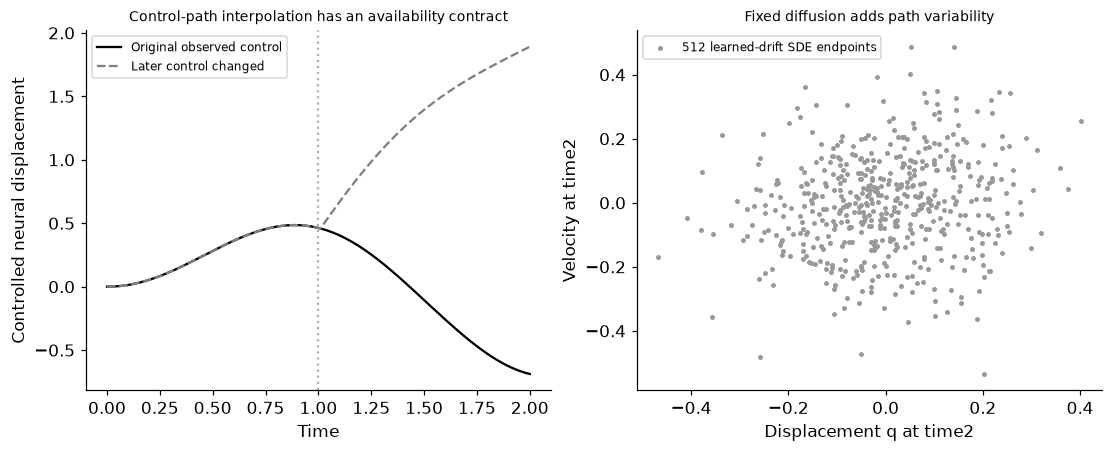

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].plot(np.arange(201)*dt,controlled_path[:,0],color='black',label='Original observed control');axes[0].plot(np.arange(201)*dt,changed_path[:,0],'--',color='.5',label='Later control changed');axes[0].axvline(1,color='.7',linestyle=':');axes[0].set(xlabel='Time',ylabel='Controlled neural displacement',title='Control-path interpolation has an availability contract');axes[0].legend(fontsize=8)
axes[1].scatter(fine[:,0],fine[:,1],s=5,color='.6',label='512 learned-drift SDE endpoints');axes[1].set(xlabel='Displacement q at time2',ylabel='Velocity at time2',title='Fixed diffusion adds path variability');axes[1].legend(fontsize=8);plt.show()
assert all(np.isfinite(r['final_rollout_MSE']) for r in rows)


In [4]:
summary={'example_id':'code_130','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual learned neural ODE vector field', 'positive mechanical stiffness and damping', 'differentiable RK4 and finite-difference gradient', 'controlled input-path integration', 'neural drift SDE with shared Brownian refinement'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual learned neural ODE vector field", "positive mechanical stiffness and damping", "differentiable RK4 and finite-difference gradient", "controlled input-path integration", "neural drift SDE with shared Brownian refinement"], "elapsed_seconds": 1.342, "example_id": "code_130", "hardware": "Darwin arm64 CPU", "results": {"comparisons": [{"development_derivative_MSE": 5.811806978362223e-06, "final_rollout_MSE": 4.4122916419599056e-05, "late_time_MSE": 6.212531863591613e-05, "model": "Unconstrained neural ODE", "parameters": 354, "source_derivative_MSE": 7.243995606376764e-06, "step_halving_RMS": 2.526381475816132e-07}, {"development_derivative_MSE": 1.0090845582104403e-13, "final_rollout_MSE": 5.233078320985432e-13, "late_time_MSE": 6.666654485542623e-13, "model": "Dissipative mechanical field", "parameters": 2, "source_derivative_MSE": 2.2328691536917356e-13, "step_halving_RMS": 2.516244524078867e-07}], "continuous_energy_identity_ma